# Disease prediction evaluation

Uses the saved Keras classifier and metadata ordering with supplied Testing.csv. Results are descriptive dataset metrics, not diagnostic reliability.

## Dataset consistency and overlap audit

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT);OUT=ROOT/'results'
import pandas as pd,json,numpy as np,matplotlib.pyplot as plt
from sklearn.metrics import *
tr=pd.read_csv(ROOT/'data/disease_prediction/Training.csv');te=pd.read_csv(ROOT/'data/disease_prediction/Testing.csv');meta0=json.loads((ROOT/'models/disease_prediction/metadata.json').read_text()); feats=meta0['symptoms'];labels=meta0['diseases'];print('rows',len(tr),len(te),'features',len(feats),'classes',len(labels),'metadata unique train profiles',meta0.get('training_profiles_unique'))
train_profiles=set(map(tuple,tr[feats].fillna(0).to_numpy()));overlap=sum(tuple(x) in train_profiles for x in te[feats].fillna(0).to_numpy()); print('exact train/test symptom profiles:',overlap,'of',len(te))


rows 4920 42 features 131 classes 41 metadata unique train profiles 304
exact train/test symptom profiles: 41 of 42


## Classifier metrics and plots

Softmax outputs are used as ranking scores; calibration is not assumed. Top-3 is evaluated over model class probabilities.

{'n': 42, 'accuracy': 1.0, 'macro_f1': 1.0, 'weighted_f1': 1.0, 'top3_accuracy': 1.0, 'exact_profile_overlap': 41, 'mean_max_score': 0.9971892237663269}
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         1
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         1
                    Chronic cholesta

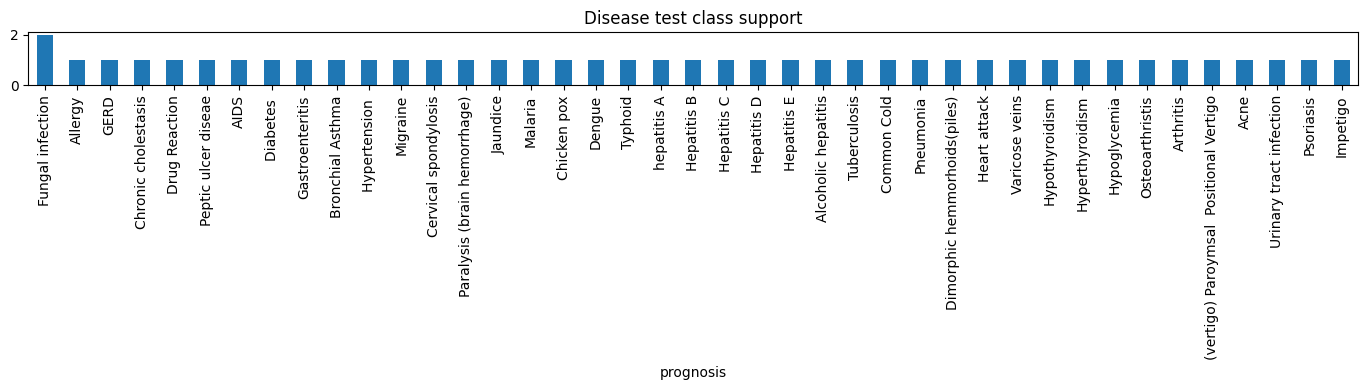

In [2]:
try:
 import tensorflow as tf
 model=tf.keras.models.load_model(ROOT/'models/disease_prediction/disease_model.keras');X=te.reindex(columns=feats).astype('float32').to_numpy();y=te.prognosis.astype(str).str.strip().to_numpy();probs=model.predict(X,verbose=0);yp=np.array(labels)[probs.argmax(1)];m={'n':len(y),'accuracy':accuracy_score(y,yp),'macro_f1':f1_score(y,yp,labels=labels,average='macro',zero_division=0),'weighted_f1':f1_score(y,yp,labels=labels,average='weighted',zero_division=0),'top3_accuracy':float(np.mean([labels.index(y[i]) in np.argsort(probs[i])[-3:] for i in range(len(y))])) if len(labels)>=3 else None,'exact_profile_overlap':overlap,'mean_max_score':float(probs.max(1).mean())};print(m);print(classification_report(y,yp,labels=labels,zero_division=0));save(OUT/'metrics/disease_prediction.json',meta(ROOT,'disease classifier',metrics=m,checkpoint=str(ROOT/'models/disease_prediction/disease_model.keras')));pd.DataFrame({'truth':y,'prediction':yp,'score':probs.max(1)}).to_csv(OUT/'tables/disease_predictions.csv',index=False)
 te.prognosis.value_counts().plot.bar(figsize=(14,4),title='Disease test class support');plt.tight_layout();plt.savefig(OUT/'figures/disease_class_support.png',dpi=150);plt.show()
except Exception as e: print('UNAVAILABLE:',type(e).__name__,str(e))


## Baselines and interpretation

A majority-class baseline can be added when train/test labels are verified compatible. Exact profile overlap is checked above and may undermine held-out interpretation. The interactive app also applies a hybrid ranking step; this notebook reports the neural classifier head.

## Confusion and per-disease performance

These plots use the same saved-model test predictions. One-example-per-class test support and near-complete profile overlap sharply limit conclusions.

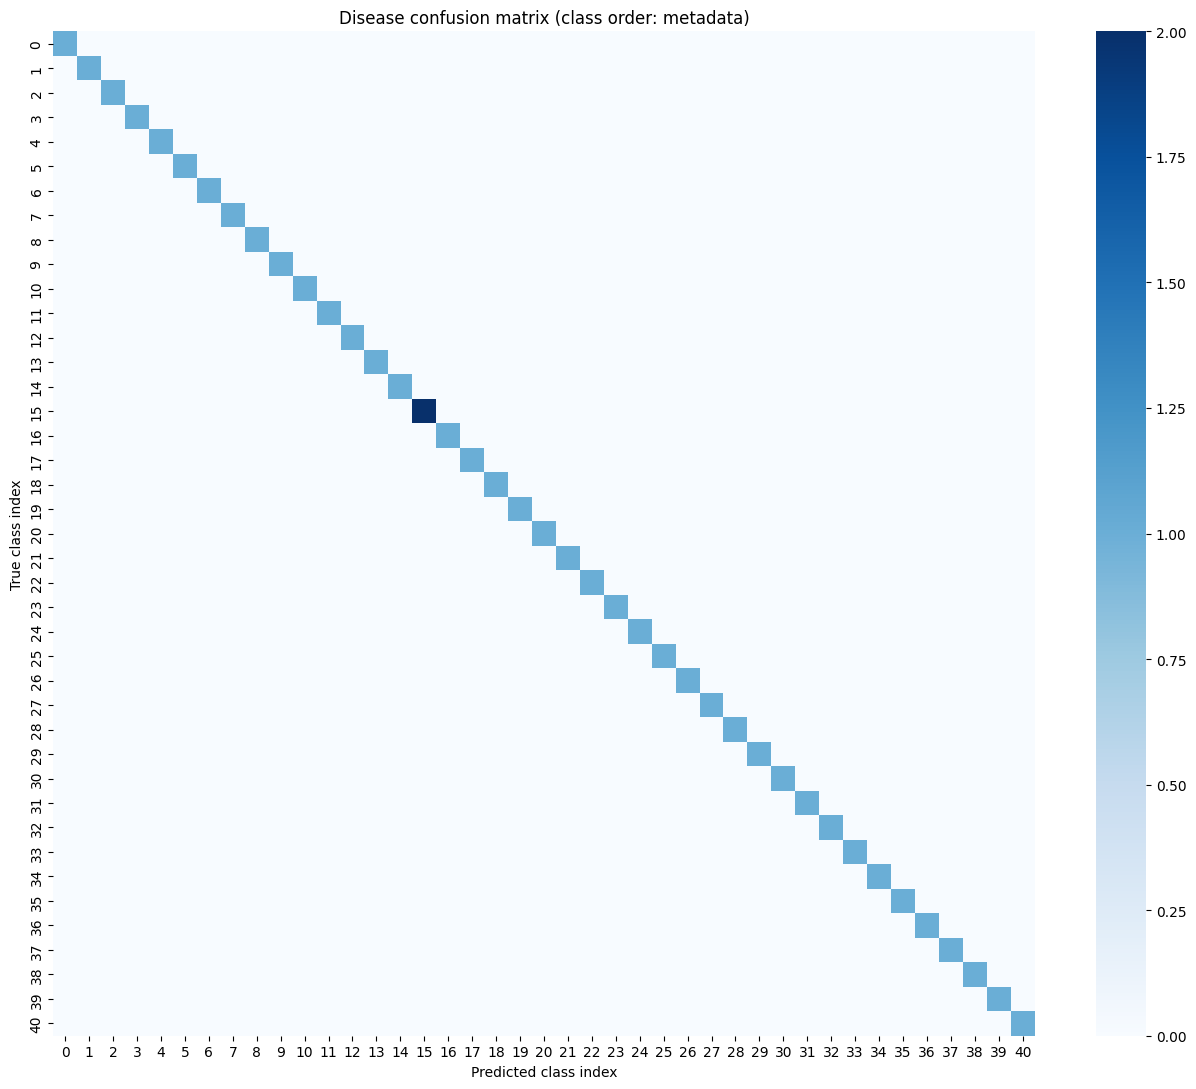

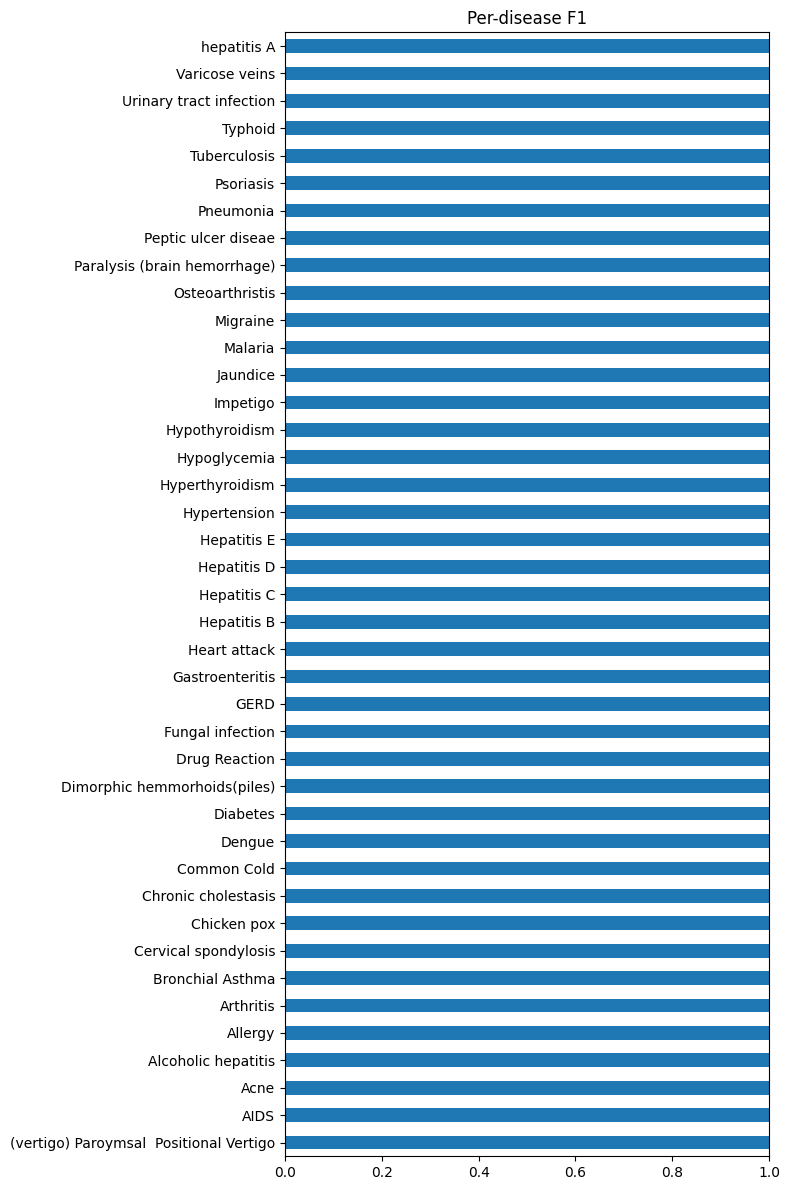

In [3]:
if 'yp' in globals():
 from sklearn.metrics import confusion_matrix,classification_report
 import seaborn as sns
 cm=confusion_matrix(y,yp,labels=labels);fig,ax=plt.subplots(figsize=(13,11));sns.heatmap(cm,ax=ax,cmap='Blues');ax.set_xlabel('Predicted class index');ax.set_ylabel('True class index');ax.set_title('Disease confusion matrix (class order: metadata)');plt.tight_layout();plt.savefig(OUT/'figures/disease_confusion_matrix.png',dpi=150);plt.show()
 rep=classification_report(y,yp,labels=labels,output_dict=True,zero_division=0);f=pd.Series({k:v['f1-score'] for k,v in rep.items() if k in labels}).sort_values();f.plot.barh(figsize=(8,12),title='Per-disease F1');plt.xlim(0,1);plt.tight_layout();plt.savefig(OUT/'figures/disease_per_class_f1.png',dpi=150);plt.show()
else: print('Disease charts NOT RUN: model evaluation unavailable.')